
# CA1 - Data Analytics for Business
## Task 2 - Recommendation System Development

**Student ID:** N00235865

**Assigned Stakeholder:** Commercial Director

### Project Objective

The objective of this task is to analyse customer purchasing behaviour and product performance, and develop recommendation systems that can support customer engagement and increase business value.

Two recommendation approaches will be developed and evaluated using the allocated customer, product and transaction datasets.


In [2]:

# 2.1 Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import precision_score, recall_score

print("Libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [5]:
customers = pd.read_csv("../data/Customers_list.csv")
products = pd.read_csv("../data/Products_list.csv")
transactions = pd.read_csv("../data/Transactions_list.csv")

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


In [6]:
print("CUSTOMERS:", customers.shape)
print("PRODUCTS:", products.shape)
print("TRANSACTIONS:", transactions.shape)

CUSTOMERS: (1000, 5)
PRODUCTS: (200, 6)
TRANSACTIONS: (18829, 5)


In [7]:
print("CUSTOMERS")
display(customers.head())
print(customers.info())

print("\nPRODUCTS")
display(products.head())
print(products.info())

print("\nTRANSACTIONS")
display(transactions.head())
print(transactions.info())

CUSTOMERS


,CustomerID,AgeGroup,Region,LoyaltyLevel,MembershipYears
0,1,50+,South,Bronze,8
1,2,26-35,South,Bronze,1
2,3,26-35,West,Bronze,2
3,4,50+,West,Silver,2
4,5,26-35,South,Bronze,8


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       1000 non-null   int64
 1   AgeGroup         1000 non-null   str  
 2   Region           1000 non-null   str  
 3   LoyaltyLevel     1000 non-null   str  
 4   MembershipYears  1000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 39.2 KB
None

PRODUCTS


,ProductID,Category,Brand,Price,Rating,PopularityScore
0,1,Fitness,PrimeGoods,66.68,4.35,1
1,2,Kitchen,FitLife,367.01,NaN,2
2,3,Books,TechMax,176.00,4.57,1
3,4,Fitness,NextGen,426.37,3.39,7
4,5,Gaming,TechMax,266.57,4.19,1


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ProductID        200 non-null    int64  
 1   Category         200 non-null    str    
 2   Brand            200 non-null    str    
 3   Price            200 non-null    float64
 4   Rating           185 non-null    float64
 5   PopularityScore  200 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 9.5 KB
None

TRANSACTIONS


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,171,1,82,462.89
1,2,48,4,255,433.60
2,2,112,3,315,1264.65
3,3,1,1,53,460.84
4,4,44,4,269,767.68


<class 'pandas.DataFrame'>
RangeIndex: 18829 entries, 0 to 18828
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        18829 non-null  int64  
 1   ProductID         18829 non-null  int64  
 2   PurchaseCount     18829 non-null  int64  
 3   LastPurchaseDays  18829 non-null  int64  
 4   Spend             18829 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 735.6 KB
None


### 2.2 Data Quality Assessment

In [8]:
# Check missing values
print("MISSING VALUES")

print("\nCustomers:")
print(customers.isnull().sum())

print("\nProducts:")
print(products.isnull().sum())

print("\nTransactions:")
print(transactions.isnull().sum())


# Check duplicate records
print("\nDUPLICATE RECORDS")

print("Customers:", customers.duplicated().sum())
print("Products:", products.duplicated().sum())
print("Transactions:", transactions.duplicated().sum())


# Check customer and product ID matching
print("\nID VALIDATION")

print(
    "Unknown CustomerIDs:",
    (~transactions["CustomerID"].isin(customers["CustomerID"])).sum()
)

print(
    "Unknown ProductIDs:",
    (~transactions["ProductID"].isin(products["ProductID"])).sum()
)

MISSING VALUES

Customers:
CustomerID         0
AgeGroup           0
Region             0
LoyaltyLevel       0
MembershipYears    0
dtype: int64

Products:
ProductID           0
Category            0
Brand               0
Price               0
Rating             15
PopularityScore     0
dtype: int64

Transactions:
CustomerID          0
ProductID           0
PurchaseCount       0
LastPurchaseDays    0
Spend               0
dtype: int64

DUPLICATE RECORDS
Customers: 0
Products: 0
Transactions: 386

ID VALIDATION
Unknown CustomerIDs: 0
Unknown ProductIDs: 0


In [10]:
## check duplicates 
print("Customer duplicates:", customers.duplicated().sum())
print("Product duplicates:", products.duplicated().sum())
print("Transaction duplicates:", transactions.duplicated().sum())

Customer duplicates: 0
Product duplicates: 0
Transaction duplicates: 386


In [11]:
## investigate missing values
print("Missing ratings:", products["Rating"].isnull().sum())

print("\nRating statistics:")
print(products["Rating"].describe())

print("\nProducts with missing ratings:")
display(products[products["Rating"].isnull()])

Missing ratings: 15

Rating statistics:
count    185.000000
mean       3.830703
std        0.766830
min        2.510000
25%        3.150000
50%        3.870000
75%        4.520000
max        5.000000
Name: Rating, dtype: float64

Products with missing ratings:


,ProductID,Category,Brand,Price,Rating,PopularityScore
1,2,Kitchen,FitLife,367.01,NaN,2
25,26,Books,TechMax,218.60,NaN,1
28,29,Home,TechMax,298.60,NaN,5
34,35,Gaming,FitLife,224.62,NaN,5
53,54,Books,PrimeGoods,173.92,NaN,1
67,68,Books,NextGen,134.04,NaN,1
72,73,Gaming,TechMax,415.14,NaN,3
86,87,Electronics,PrimeGoods,360.52,NaN,1
91,92,Kitchen,FitLife,37.03,NaN,3
95,96,Kitchen,PrimeGoods,442.25,NaN,2


In [12]:
## investigating 386 duplicate transactions
duplicate_transactions = transactions[
    transactions.duplicated(keep=False)
]

print("Rows involved in duplicate groups:", len(duplicate_transactions))

display(duplicate_transactions.head(20))

Rows involved in duplicate groups: 770


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
4,4,44,4,269,767.68
22,17,27,3,147,895.41
108,53,186,2,303,641.16
131,54,161,1,8,298.26
134,54,72,4,224,1369.48
142,54,161,1,8,298.26
153,55,64,2,78,332.48
201,57,101,3,105,1471.32
205,57,55,2,278,33.04
213,58,166,4,196,1573.32


In [13]:
# Check repeated CustomerID and ProductID combinations
customer_product_counts = transactions.groupby(
    ["CustomerID", "ProductID"]
).size().reset_index(name="RecordCount")

repeated_pairs = customer_product_counts[
    customer_product_counts["RecordCount"] > 1
]

print("Repeated customer-product pairs:", len(repeated_pairs))

display(repeated_pairs.head(20))

Repeated customer-product pairs: 3420


,CustomerID,ProductID,RecordCount
4,4,44,3
21,17,27,2
37,28,64,2
53,41,64,2
68,51,64,8
69,51,71,3
71,52,12,6
74,52,110,2
79,53,12,4
81,53,64,13


In [14]:
# Create working copies
customers_clean = customers.copy()
products_clean = products.copy()
transactions_clean = transactions.copy()

# Remove exact duplicate transaction records
transactions_clean = transactions_clean.drop_duplicates()

print("Original transaction records:", len(transactions))
print("Cleaned transaction records:", len(transactions_clean))
print("Exact duplicates removed:", len(transactions) - len(transactions_clean))

Original transaction records: 18829
Cleaned transaction records: 18443
Exact duplicates removed: 386


In [15]:
## retain prodcuts and leave missing ratings as nan
print("Products retained:", len(products_clean))
print("Missing ratings retained:", products_clean["Rating"].isnull().sum())

Products retained: 200
Missing ratings retained: 15


In [16]:
## checking cleaned datasets
print("CUSTOMERS:", customers_clean.shape)
print("PRODUCTS:", products_clean.shape)
print("TRANSACTIONS:", transactions_clean.shape)

print("\nRemaining exact duplicates:")
print("Customers:", customers_clean.duplicated().sum())
print("Products:", products_clean.duplicated().sum())
print("Transactions:", transactions_clean.duplicated().sum())

CUSTOMERS: (1000, 5)
PRODUCTS: (200, 6)
TRANSACTIONS: (18443, 5)

Remaining exact duplicates:
Customers: 0
Products: 0
Transactions: 0


### 2.3 Data Integration

In [17]:
# Merge transactions with customer information
customer_transactions = transactions_clean.merge(
    customers_clean,
    on="CustomerID",
    how="left"
)

# Add product information
integrated_data = customer_transactions.merge(
    products_clean,
    on="ProductID",
    how="left"
)

print("Integrated dataset shape:", integrated_data.shape)

display(integrated_data.head())

Integrated dataset shape: (18443, 14)


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend,AgeGroup,Region,LoyaltyLevel,MembershipYears,Category,Brand,Price,Rating,PopularityScore
0,1,171,1,82,462.89,50+,South,Bronze,8,Electronics,TechMax,449.12,4.36,2
1,2,48,4,255,433.60,26-35,South,Bronze,1,Gaming,FitLife,273.31,3.90,8
2,2,112,3,315,1264.65,26-35,South,Bronze,1,Home,NextGen,205.16,3.07,15
3,3,1,1,53,460.84,26-35,West,Bronze,2,Fitness,PrimeGoods,66.68,4.35,1
4,4,44,4,269,767.68,50+,West,Silver,2,Gaming,TechMax,136.66,4.72,1


In [18]:
print("Missing values after integration:")
print(integrated_data.isnull().sum())

print("\nUnique customers:", integrated_data["CustomerID"].nunique())
print("Unique products:", integrated_data["ProductID"].nunique())

Missing values after integration:
CustomerID             0
ProductID              0
PurchaseCount          0
LastPurchaseDays       0
Spend                  0
AgeGroup               0
Region                 0
LoyaltyLevel           0
MembershipYears        0
Category               0
Brand                  0
Price                  0
Rating              1213
PopularityScore        0
dtype: int64

Unique customers: 1000
Unique products: 200


### 2.4 Customer-Product Interaction Matrix

In [19]:
# Create customer-product interaction matrix
interaction_matrix = transactions_clean.pivot_table(
    index="CustomerID",
    columns="ProductID",
    values="PurchaseCount",
    aggfunc="sum",
    fill_value=0
)

print("Interaction matrix shape:", interaction_matrix.shape)

display(interaction_matrix.head())

Interaction matrix shape: (1000, 200)


ProductID,1,2,3,4,5,6,7,8,9,10,...,191,192,193,194,195,196,197,198,199,200
CustomerID,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [20]:
# Check interaction matrix
print("Number of customers:", interaction_matrix.shape[0])
print("Number of products:", interaction_matrix.shape[1])
print("Total recorded interactions:", (interaction_matrix > 0).sum().sum())
print("Matrix density:", round(
    (interaction_matrix > 0).sum().sum() /
    interaction_matrix.size * 100, 2
), "%")

Number of customers: 1000
Number of products: 200
Total recorded interactions: 10263
Matrix density: 5.13 %


### 2.5 Customer Analytics

In [21]:
# Aggregate customer purchasing behaviour
customer_summary = integrated_data.groupby("CustomerID").agg(
    TotalSpend=("Spend", "sum"),
    TotalPurchases=("PurchaseCount", "sum"),
    UniqueProducts=("ProductID", "nunique"),
    AverageSpend=("Spend", "mean")
).reset_index()

# Add customer information
customer_summary = customer_summary.merge(
    customers_clean,
    on="CustomerID",
    how="left"
)

display(customer_summary.head())

,CustomerID,TotalSpend,TotalPurchases,UniqueProducts,AverageSpend,AgeGroup,Region,LoyaltyLevel,MembershipYears
0,1,462.89,1,1,462.890,50+,South,Bronze,8
1,2,1698.25,7,2,849.125,26-35,South,Bronze,1
2,3,460.84,1,1,460.840,26-35,West,Bronze,2
3,4,959.60,5,1,479.800,50+,West,Silver,2
4,5,625.82,2,1,625.820,26-35,South,Bronze,8


In [22]:
top_10_spenders = customer_summary.sort_values(
    by="TotalSpend",
    ascending=False
).head(10)

display(top_10_spenders)

,CustomerID,TotalSpend,TotalPurchases,UniqueProducts,AverageSpend,AgeGroup,Region,LoyaltyLevel,MembershipYears
728,729,23828.03,73,15,821.656207,18-25,East,Bronze,1
659,660,23301.22,74,15,803.490345,36-50,West,Bronze,1
893,894,23127.86,70,13,889.533077,50+,South,Bronze,5
480,481,22819.08,76,14,845.151111,26-35,South,Silver,11
73,74,22564.03,82,17,778.070000,26-35,South,Bronze,5
82,83,21968.20,67,17,757.524138,26-35,West,Gold,2
706,707,21746.12,68,16,836.389231,26-35,West,Bronze,5
543,544,21681.06,72,16,747.622759,26-35,South,Bronze,5
575,576,21668.43,78,15,773.872500,18-25,East,Bronze,10
817,818,21549.61,68,14,861.984400,26-35,North,Silver,1


In [23]:
top_10_purchasers = customer_summary.sort_values(
    by="TotalPurchases",
    ascending=False
).head(10)

display(top_10_purchasers)

,CustomerID,TotalSpend,TotalPurchases,UniqueProducts,AverageSpend,AgeGroup,Region,LoyaltyLevel,MembershipYears
449,450,16211.05,83,18,578.966071,18-25,South,Bronze,12
373,374,16055.06,82,14,573.395000,18-25,South,Bronze,14
297,298,18909.03,82,15,652.035517,26-35,East,Bronze,1
73,74,22564.03,82,17,778.070000,26-35,South,Bronze,5
879,880,17152.34,82,7,591.460000,26-35,West,Silver,4
328,329,19415.12,81,14,746.735385,36-50,North,Silver,7
239,240,20688.72,81,15,713.404138,36-50,East,Bronze,5
167,168,21100.45,80,15,727.601724,26-35,West,Silver,2
64,65,21168.14,79,13,729.935862,26-35,East,Gold,4
680,681,15191.96,78,16,523.860690,50+,West,Gold,3


### 2.6 Customer Value Analysis

In [24]:
# Calculate customer spending quartiles
print(customer_summary["TotalSpend"].describe())

# Create customer value segments
customer_summary["CustomerValue"] = pd.qcut(
    customer_summary["TotalSpend"],
    q=4,
    labels=["Low Value", "Medium Value", "High Value", "Top Value"]
)

# Summarise customer value segments
customer_value_analysis = customer_summary.groupby(
    "CustomerValue",
    observed=True
).agg(
    CustomerCount=("CustomerID", "count"),
    AverageSpend=("TotalSpend", "mean"),
    TotalRevenue=("TotalSpend", "sum"),
    AveragePurchases=("TotalPurchases", "mean")
).reset_index()

display(customer_value_analysis)

count     1000.000000
mean     11098.860370
std       4622.822638
min        105.420000
25%       7844.507500
50%      11133.480000
75%      14375.957500
max      23828.030000
Name: TotalSpend, dtype: float64


,CustomerValue,CustomerCount,AverageSpend,TotalRevenue,AveragePurchases
0,Low Value,250,5229.94672,1307486.68,24.384
1,Medium Value,250,9518.00244,2379500.61,41.408
2,High Value,250,12752.69228,3188173.07,53.720
3,Top Value,250,16894.80004,4223700.01,64.296


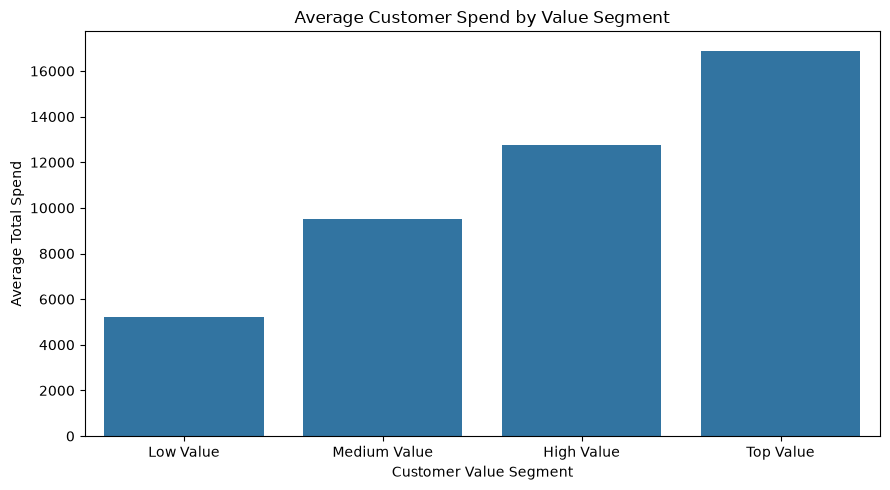

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_value_analysis,
    x="CustomerValue",
    y="AverageSpend"
)

plt.title("Average Customer Spend by Value Segment")
plt.xlabel("Customer Value Segment")
plt.ylabel("Average Total Spend")
plt.tight_layout()
plt.show()

### 2.7 Product Analytics

In [26]:
# Revenue generated by each product
product_revenue = integrated_data.groupby(
    ["ProductID", "Category", "Brand"]
).agg(
    TotalRevenue=("Spend", "sum"),
    TotalPurchases=("PurchaseCount", "sum"),
    NumberOfCustomers=("CustomerID", "nunique")
).reset_index()

# Top 10 products by revenue
top_10_products = product_revenue.sort_values(
    by="TotalRevenue",
    ascending=False
).head(10)

display(top_10_products)

,ProductID,Category,Brand,TotalRevenue,TotalPurchases,NumberOfCustomers
63,64,Books,PrimeGoods,969511.68,5832,183
75,76,Kitchen,FitLife,516181.63,2383,177
72,73,Gaming,TechMax,513764.73,1041,160
136,137,Fitness,NextGen,377406.54,1447,166
17,18,Gaming,SmartBuy,285252.63,601,114
46,47,gaming,NextGen,285250.14,621,125
11,12,fitness,PrimeGoods,270583.58,2326,189
5,6,Kitchen,SmartBuy,207772.24,664,136
43,44,Gaming,TechMax,201899.84,1052,150
18,19,Kitchen,PrimeGoods,198754.95,465,117


In [27]:
# Revenue by product category
category_revenue = integrated_data.groupby("Category").agg(
    TotalRevenue=("Spend", "sum"),
    TotalPurchases=("PurchaseCount", "sum"),
    UniqueCustomers=("CustomerID", "nunique")
).reset_index().sort_values(
    by="TotalRevenue",
    ascending=False
)

display(category_revenue)

,Category,TotalRevenue,TotalPurchases,UniqueCustomers
0,Books,2122416.77,10377,845
3,Gaming,1996015.62,6706,793
5,Kitchen,1830066.69,6999,759
2,Fitness,1403313.00,6123,745
1,Electronics,1214549.28,4716,783
4,Home,1148351.73,5304,728
8,fitness,423298.28,2772,280
9,gaming,285250.14,621,125
7,electronics,231089.37,855,259
6,books,212787.70,470,108


In [28]:
# Revenue by brand
brand_revenue = integrated_data.groupby("Brand").agg(
    TotalRevenue=("Spend", "sum"),
    TotalPurchases=("PurchaseCount", "sum"),
    UniqueCustomers=("CustomerID", "nunique")
).reset_index().sort_values(
    by="TotalRevenue",
    ascending=False
)

display(brand_revenue)

,Brand,TotalRevenue,TotalPurchases,UniqueCustomers
5,TechMax,2615417.61,10240,913
3,PrimeGoods,2454682.07,13997,882
0,FitLife,1712054.34,6656,657
2,NextGen,1536967.99,5557,741
4,SmartBuy,1420657.50,4874,765
1,HomePro,1359080.86,4628,714


In [29]:
# Clean category names
# Standardise product category names
products_clean["Category"] = (
    products_clean["Category"].str.strip().str.title()
)

# Rebuild integrated dataset using cleaned product data
customer_transactions = transactions_clean.merge(
    customers_clean,
    on="CustomerID",
    how="left"
)

integrated_data = customer_transactions.merge(
    products_clean,
    on="ProductID",
    how="left"
)

print("Standardised categories:")
print(products_clean["Category"].unique())

Standardised categories:
<StringArray>
['Fitness', 'Kitchen', 'Books', 'Gaming', 'Home', 'Electronics']
Length: 6, dtype: str


In [30]:
category_revenue = integrated_data.groupby("Category").agg(
    TotalRevenue=("Spend", "sum"),
    TotalPurchases=("PurchaseCount", "sum"),
    UniqueCustomers=("CustomerID", "nunique")
).reset_index().sort_values(
    by="TotalRevenue",
    ascending=False
)

display(category_revenue)

,Category,TotalRevenue,TotalPurchases,UniqueCustomers
0,Books,2335204.47,10847,861
3,Gaming,2281265.76,7327,800
5,Kitchen,1868036.68,7163,770
2,Fitness,1826611.28,8895,789
1,Electronics,1445638.65,5571,841
4,Home,1342103.53,6149,760


In [31]:
# Pivot table: Revenue by category and brand
category_brand_pivot = pd.pivot_table(
    integrated_data,
    values="Spend",
    index="Category",
    columns="Brand",
    aggfunc="sum",
    fill_value=0
)

display(category_brand_pivot)

Brand,FitLife,HomePro,NextGen,PrimeGoods,SmartBuy,TechMax
Category,,,,,,
Books,142105.12,283673.98,126234.09,1170113.24,98048.55,515029.49
Electronics,280132.64,173919.80,351161.51,181105.08,132029.28,327290.34
Fitness,266447.04,213868.28,540589.86,537873.11,91542.73,176290.26
Gaming,263341.84,89321.80,323835.16,12695.40,438243.75,1153827.81
Home,88735.42,544092.15,74745.06,239689.85,60792.93,334048.12
Kitchen,671292.28,54204.85,120402.31,313205.39,600000.26,108931.59


In [32]:
# Pivot table: Purchase frequency by loyalty level and category
loyalty_category_pivot = pd.pivot_table(
    integrated_data,
    values="PurchaseCount",
    index="LoyaltyLevel",
    columns="Category",
    aggfunc="sum",
    fill_value=0
)

display(loyalty_category_pivot)

Category,Books,Electronics,Fitness,Gaming,Home,Kitchen
LoyaltyLevel,,,,,,
Bronze,5437,2566,4412,3622,2889,3535
Gold,1837,1109,1624,1408,1350,1317
Silver,3573,1896,2859,2297,1910,2311


In [33]:
print("Popularity score distribution:")
print(products_clean["PopularityScore"].describe())

print("\nMost popular products:")
display(
    products_clean.sort_values(
        by="PopularityScore",
        ascending=False
    ).head(10)
)

Popularity score distribution:
count    200.000000
mean       3.665000
std       12.372476
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max      131.000000
Name: PopularityScore, dtype: float64

Most popular products:


,ProductID,Category,Brand,Price,Rating,PopularityScore
81,82,Books,PrimeGoods,66.52,3.15,131
68,69,Electronics,TechMax,100.46,4.27,107
46,47,Gaming,NextGen,116.36,4.60,43
113,114,Home,PrimeGoods,321.76,2.66,21
54,55,Electronics,PrimeGoods,468.04,3.94,16
111,112,Home,NextGen,205.16,3.07,15
69,70,Fitness,FitLife,417.18,4.84,15
42,43,Kitchen,HomePro,434.82,3.47,13
101,102,Home,HomePro,474.99,4.42,10
107,108,Fitness,SmartBuy,454.02,4.03,10


### 2.8 Popularity-Based Recommendation System

In [36]:
# Calculate overall product popularity from actual purchases
product_popularity = transactions_clean.groupby(
    "ProductID"
).agg(
    TotalPurchases=("PurchaseCount", "sum"),
    TotalRevenue=("Spend", "sum"),
    NumberOfCustomers=("CustomerID", "nunique")
).reset_index()

# Add product details
product_popularity = product_popularity.merge(
    products_clean,
    on="ProductID",
    how="left"
)

# Rank products by total purchase frequency
product_popularity = product_popularity.sort_values(
    by="TotalPurchases",
    ascending=False
).reset_index(drop=True)

print("Top 10 most purchased products:")
display(
    product_popularity[
        ["ProductID", "Category", "Brand", "TotalPurchases",
         "TotalRevenue", "PopularityScore"]
    ].head(10)
)


Top 10 most purchased products:


,ProductID,Category,Brand,TotalPurchases,TotalRevenue,PopularityScore
0,64,Books,PrimeGoods,5832,969511.68,1
1,76,Kitchen,FitLife,2383,516181.63,1
2,12,Fitness,PrimeGoods,2326,270583.58,1
3,137,Fitness,NextGen,1447,377406.54,1
4,198,Fitness,PrimeGoods,1405,74493.10,1
5,44,Gaming,TechMax,1052,201899.84,1
6,73,Gaming,TechMax,1041,513764.73,3
7,114,Home,PrimeGoods,873,126873.09,21
8,6,Kitchen,SmartBuy,664,207772.24,1
9,47,Gaming,NextGen,621,285250.14,43


In [37]:
# Popularity-based recommendation function

def recommend_popular_products(customer_id, number_of_recommendations=5):

    # Find products already purchased by this customer
    purchased_products = transactions_clean[
        transactions_clean["CustomerID"] == customer_id
    ]["ProductID"].unique()

    # Exclude products already purchased
    recommendations = product_popularity[
        ~product_popularity["ProductID"].isin(purchased_products)
    ]

    # Return the highest-ranked remaining products
    return recommendations[
        ["ProductID", "Category", "Brand", "Price", "TotalPurchases"]
    ].head(number_of_recommendations)

In [38]:
# Test popularity-based recommendations
example_customers = [1, 25, 50, 100, 250]

for customer_id in example_customers:

    print(f"\nRecommendations for Customer {customer_id}:")

    display(
        recommend_popular_products(customer_id, 5)
    )


Recommendations for Customer 1:


,ProductID,Category,Brand,Price,TotalPurchases
0,64,Books,PrimeGoods,180.13,5832
1,76,Kitchen,FitLife,20.70,2383
2,12,Fitness,PrimeGoods,422.56,2326
3,137,Fitness,NextGen,24.58,1447
4,198,Fitness,PrimeGoods,20.24,1405



Recommendations for Customer 25:


,ProductID,Category,Brand,Price,TotalPurchases
0,64,Books,PrimeGoods,180.13,5832
1,76,Kitchen,FitLife,20.70,2383
2,12,Fitness,PrimeGoods,422.56,2326
4,198,Fitness,PrimeGoods,20.24,1405
5,44,Gaming,TechMax,136.66,1052



Recommendations for Customer 50:


,ProductID,Category,Brand,Price,TotalPurchases
0,64,Books,PrimeGoods,180.13,5832
1,76,Kitchen,FitLife,20.70,2383
2,12,Fitness,PrimeGoods,422.56,2326
3,137,Fitness,NextGen,24.58,1447
4,198,Fitness,PrimeGoods,20.24,1405



Recommendations for Customer 100:


,ProductID,Category,Brand,Price,TotalPurchases
0,64,Books,PrimeGoods,180.13,5832
1,76,Kitchen,FitLife,20.70,2383
2,12,Fitness,PrimeGoods,422.56,2326
3,137,Fitness,NextGen,24.58,1447
4,198,Fitness,PrimeGoods,20.24,1405



Recommendations for Customer 250:


,ProductID,Category,Brand,Price,TotalPurchases
0,64,Books,PrimeGoods,180.13,5832
1,76,Kitchen,FitLife,20.70,2383
2,12,Fitness,PrimeGoods,422.56,2326
3,137,Fitness,NextGen,24.58,1447
4,198,Fitness,PrimeGoods,20.24,1405


### 2.9 Item-Based Collaborative Filtering

In [46]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between products
item_similarity = cosine_similarity(interaction_matrix.T)

# Convert similarity scores into a DataFrame
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=interaction_matrix.columns,
    columns=interaction_matrix.columns
)

print("Item similarity matrix:", item_similarity_df.shape)

display(item_similarity_df.iloc[:5, :5])

Item similarity matrix: (200, 200)


ProductID,1,2,3,4,5
ProductID,,,,,
1,1.0,0.000000,0.0,0.000000,0.0
2,0.0,1.000000,0.0,0.304484,0.0
3,0.0,0.000000,1.0,0.000000,0.0
4,0.0,0.304484,0.0,1.000000,0.0
5,0.0,0.000000,0.0,0.000000,1.0


In [45]:
def recommend_similar_products(customer_id, number_of_recommendations=5):

    # Get the customer's purchase history
    customer_history = interaction_matrix.loc[customer_id]

    # Calculate recommendation scores using product similarities
    recommendation_scores = item_similarity_df.dot(customer_history)

    # Exclude products already purchased
    recommendation_scores = recommendation_scores[
        customer_history == 0
    ]

    # Sort products by recommendation score
    top_recommendations = recommendation_scores.sort_values(
        ascending=False
    ).head(number_of_recommendations)

    # Add product details
    recommendations = products_clean[
        products_clean["ProductID"].isin(top_recommendations.index)
    ].copy()

    recommendations["RecommendationScore"] = (
        recommendations["ProductID"].map(top_recommendations)
    )

    return recommendations.sort_values(
        by="RecommendationScore",
        ascending=False
    )[[
        "ProductID",
        "Category",
        "Brand",
        "Price",
        "RecommendationScore"
    ]]

In [47]:
example_customers = [1, 25, 50, 100, 250]

for customer_id in example_customers:

    print(f"\nCollaborative recommendations for Customer {customer_id}:")

    display(
        recommend_similar_products(customer_id, 5)
    )


Collaborative recommendations for Customer 1:


,ProductID,Category,Brand,Price,RecommendationScore
100,101,Books,TechMax,82.62,0.437919
113,114,Home,PrimeGoods,321.76,0.396999
43,44,Gaming,TechMax,136.66,0.347188
94,95,Electronics,NextGen,275.20,0.346921
18,19,Kitchen,PrimeGoods,225.84,0.325813



Collaborative recommendations for Customer 25:


,ProductID,Category,Brand,Price,RecommendationScore
197,198,Fitness,PrimeGoods,20.24,0.734478
72,73,Gaming,TechMax,415.14,0.724953
7,8,Home,TechMax,99.46,0.608611
126,127,Electronics,NextGen,154.05,0.577186
154,155,Books,FitLife,441.57,0.574639



Collaborative recommendations for Customer 50:


,ProductID,Category,Brand,Price,RecommendationScore
63,64,Books,PrimeGoods,180.13,2.066216
185,186,Electronics,TechMax,266.38,1.501382
44,45,Gaming,FitLife,230.20,1.054407
90,91,Fitness,SmartBuy,298.51,1.030814
116,117,Fitness,NextGen,181.43,0.914648



Collaborative recommendations for Customer 100:


,ProductID,Category,Brand,Price,RecommendationScore
2,3,Books,TechMax,176.00,15.463470
26,27,Gaming,TechMax,16.39,14.809939
162,163,Kitchen,SmartBuy,237.67,13.750320
180,181,Electronics,HomePro,82.72,12.061757
145,146,Home,HomePro,294.32,11.849026



Collaborative recommendations for Customer 250:


,ProductID,Category,Brand,Price,RecommendationScore
43,44,Gaming,TechMax,136.66,13.200402
46,47,Gaming,NextGen,116.36,11.933873
100,101,Books,TechMax,82.62,10.175884
59,60,Books,TechMax,295.24,9.987450
141,142,Fitness,HomePro,458.31,9.664874


In [49]:
from sklearn.model_selection import train_test_split

# Create fresh training and testing matrices
train_matrix = interaction_matrix.copy()

test_matrix = pd.DataFrame(
    0,
    index=interaction_matrix.index,
    columns=interaction_matrix.columns
)

# Hold out 20% of purchased products for each eligible customer
for customer_id in interaction_matrix.index:

    purchased_products = interaction_matrix.loc[customer_id]
    purchased_products = purchased_products[purchased_products > 0]

    if len(purchased_products) >= 2:

        train_products, test_products = train_test_split(
            purchased_products.index,
            test_size=0.2,
            random_state=42
        )

        # Remove held-out products from training data
        train_matrix.loc[customer_id, test_products] = 0

        # Store held-out purchases in testing data
        test_matrix.loc[customer_id, test_products] = (
            interaction_matrix.loc[customer_id, test_products]
        )

print("Training interactions:", (train_matrix > 0).sum().sum())
print("Testing interactions:", (test_matrix > 0).sum().sum())

print("Training matrix shape:", train_matrix.shape)
print("Testing matrix shape:", test_matrix.shape)

Training interactions: 7839
Testing interactions: 2424
Training matrix shape: (1000, 200)
Testing matrix shape: (1000, 200)


In [50]:
# Calculate item similarity using training data only
train_item_similarity = cosine_similarity(train_matrix.T)

train_item_similarity_df = pd.DataFrame(
    train_item_similarity,
    index=train_matrix.columns,
    columns=train_matrix.columns
)

print("Training similarity matrix:", train_item_similarity_df.shape)

Training similarity matrix: (200, 200)


In [52]:
# Popularity ranking using training data only
train_popularity = train_matrix.sum(axis=0).sort_values(
    ascending=False
)


# Popularity-based recommendations
def evaluate_popularity_recommendations(customer_id, k=5):

    # Products already purchased in training data
    purchased = train_matrix.loc[customer_id]
    purchased = purchased[purchased > 0].index

    # Recommend the most popular products not already purchased
    candidates = train_popularity.drop(
        index=purchased,
        errors="ignore"
    )

    return candidates.head(k).index.tolist()


# Collaborative filtering recommendations
def evaluate_collaborative_recommendations(customer_id, k=5):

    # Customer's training purchase history
    customer_history = train_matrix.loc[customer_id]

    # Calculate recommendation scores
    scores = train_item_similarity_df.dot(customer_history)

    # Exclude products already purchased
    scores = scores[customer_history == 0]

    return scores.sort_values(
        ascending=False
    ).head(k).index.tolist()


print("Both evaluation recommendation functions created successfully!")

Both evaluation recommendation functions created successfully!


In [53]:
# Evaluate both recommendation systems
popularity_precision = []
popularity_recall = []

collaborative_precision = []
collaborative_recall = []

for customer_id in test_matrix.index:

    actual_products = set(
        test_matrix.loc[customer_id][
            test_matrix.loc[customer_id] > 0
        ].index
    )

    # Only evaluate customers with held-out purchases
    if len(actual_products) == 0:
        continue

    # Popularity recommendations
    popular_recommendations = set(
        evaluate_popularity_recommendations(customer_id, 5)
    )

    popular_hits = len(popular_recommendations & actual_products)

    popularity_precision.append(popular_hits / 5)
    popularity_recall.append(popular_hits / len(actual_products))

    # Collaborative recommendations
    collaborative_recommendations = set(
        evaluate_collaborative_recommendations(customer_id, 5)
    )

    collaborative_hits = len(
        collaborative_recommendations & actual_products
    )

    collaborative_precision.append(collaborative_hits / 5)
    collaborative_recall.append(
        collaborative_hits / len(actual_products)
    )


# Display average evaluation results
print("POPULARITY-BASED SYSTEM")
print("Precision@5:", round(np.mean(popularity_precision), 4))
print("Recall@5:", round(np.mean(popularity_recall), 4))

print("\nCOLLABORATIVE FILTERING SYSTEM")
print("Precision@5:", round(np.mean(collaborative_precision), 4))
print("Recall@5:", round(np.mean(collaborative_recall), 4))

POPULARITY-BASED SYSTEM
Precision@5: 0.046
Recall@5: 0.1278

COLLABORATIVE FILTERING SYSTEM
Precision@5: 0.172
Recall@5: 0.3762


### 2.10 Recommendation System Evaluation

In [54]:
# Compare recommendation system performance

model_comparison = pd.DataFrame({
    "Recommendation System": [
        "Popularity-Based",
        "Collaborative Filtering"
    ],
    "Precision@5": [
        np.mean(popularity_precision),
        np.mean(collaborative_precision)
    ],
    "Recall@5": [
        np.mean(popularity_recall),
        np.mean(collaborative_recall)
    ]
})

display(model_comparison.round(4))

,Recommendation System,Precision@5,Recall@5
0,Popularity-Based,0.046,0.1278
1,Collaborative Filtering,0.172,0.3762


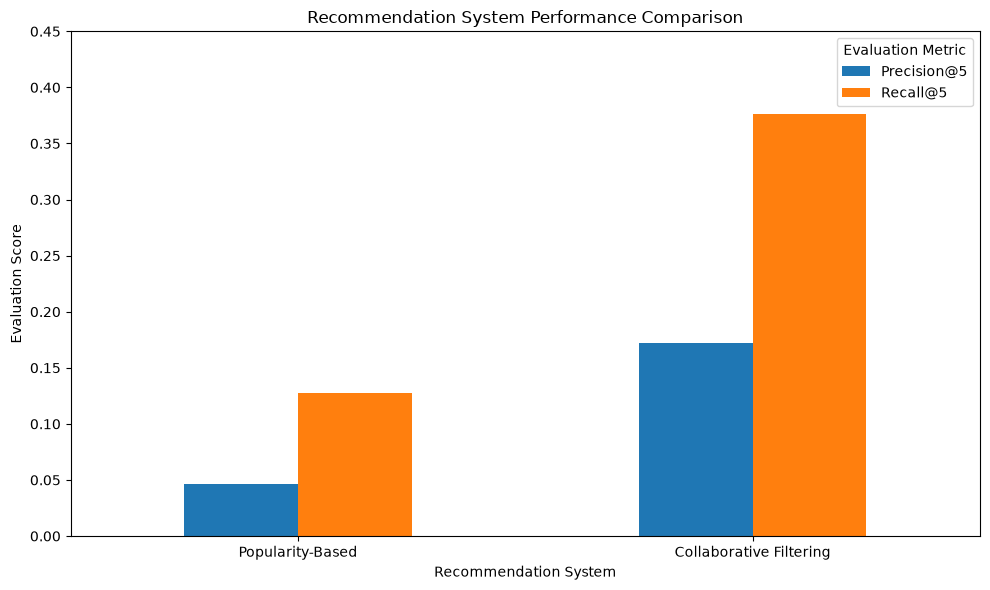

In [55]:
# Compare Precision and Recall
comparison_plot = model_comparison.set_index(
    "Recommendation System"
)

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Recommendation System Performance Comparison")
plt.ylabel("Evaluation Score")
plt.xlabel("Recommendation System")
plt.xticks(rotation=0)
plt.ylim(0, 0.45)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

In [56]:
evaluated_customers = sum(
    1 for customer_id in test_matrix.index
    if (test_matrix.loc[customer_id] > 0).any()
)

print("Customers evaluated:", evaluated_customers)

Customers evaluated: 966
